# A/B Test Analysis: Should the e-commerce site switch to the new landing page?

An e-commerce company ran an A/B test: half of the users saw the **old landing page** (control) and half saw a **new landing page** (treatment). This notebook tests whether the new page converts more users, and recommends whether to implement it, keep the old page, or run the experiment longer.

**Contents**
- [Part I - Data cleaning and probabilities](#probability)
- [Part II - A/B test (simulation and z-test)](#ab_test)
- [Part III - Logistic regression](#regression)
- [Results summary](#results)

**Data** (in `../data/`): `ab_data.csv` (294,478 rows: user_id, timestamp, group, landing_page, converted) and `countries.csv` (user country: US, UK, CA).

**Result in one line:** the new page did **not** beat the old page (see the [Results summary](#results) at the end), so the recommendation is to **keep the old page**.

<a id='probability'></a>
## Part I - Data cleaning and probabilities

First, import the libraries and set a random seed so the simulation gives the same answer every run.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Fixed seed: the simulation in Part II gives the same numbers every run
np.random.seed(42)
np.set_printoptions(legacy='1.25')  # print plain numbers instead of np.float64(...)

# Folder where the charts of this notebook are saved
IMG_DIR = '../images'
os.makedirs(IMG_DIR, exist_ok=True)

### 1.1 Load the data
Read `ab_data.csv` into `df`. The data has 5 columns:

<center>

|Data columns|Purpose|Valid values|
| ------------- |:-------------| -----:|
|user_id|Unique ID|Int64 values|
|timestamp|Time stamp when the user visited the webpage|-|
|group|In the current A/B experiment, the users are categorized into two broad groups. <br>The `control` group users are expected to be served with `old_page`; and `treatment` group users are matched with the `new_page`. <br>However, **some inaccurate rows** are present in the initial data, such as a `control` group user is matched with a `new_page`. |`['control', 'treatment']`|
|landing_page|It denotes whether the user visited the old or new webpage.|`['old_page', 'new_page']`|
|converted|It denotes whether the user decided to pay for the company's product. Here, `1` means yes, the user bought the product.|`[0, 1]`|
</center>
**a.** Read the dataset and look at the top few rows:

In [2]:
df = pd.read_csv('../data/ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


**b.** Number of rows in the dataset.

In [3]:
df.shape

(294478, 5)

**c.** The number of unique users in the dataset.

In [4]:
df.user_id.nunique()

290584

**d.** The proportion of users converted.

In [5]:
df.converted.mean()

0.11965919355605512

**e.** Rows where `group` and `landing_page` do not match (`treatment` without `new_page`, or `control` without `old_page`). They are the two off-diagonal groups below: 1,928 + 1,965 = 3,893 rows.

In [6]:
df.groupby(['landing_page', 'group'])['group'].count()

landing_page  group    
new_page      control        1928
              treatment    145311
old_page      control      145274
              treatment      1965
Name: group, dtype: int64

**f.** Are there any missing values?

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


### 1.2 Remove mismatched rows
In a particular row, the **group** and **landing_page** columns should have either of the following acceptable values:

|user_id| timestamp|group|landing_page|converted|
|---|---|---|---|---|
|XXXX|XXXX|`control`| `old_page`|X |
|XXXX|XXXX|`treatment`|`new_page`|X |


It means, the `control` group users should match with `old_page`; and `treatment` group users should matched with the `new_page`. 

For the rows where `treatment` does not match `new_page`, or `control` does not match `old_page`, we cannot be sure which page the user really saw, so these rows are dropped.

**a.** Create `df2` without the mismatched rows.

In [8]:
# Remove the inaccurate rows, and store the result in a new dataframe df2
df2 = df.drop(df[((df.landing_page == 'old_page') & (df.group == 'treatment')) | ((df.landing_page == 'new_page') & (df.group == 'control'))].index)

In [9]:
# Double Check all of the incorrect rows were removed from df2 - 
# Output of the statement below should be 0
df2[((df2['group'] == 'treatment') == (df2['landing_page'] == 'new_page')) == False].shape[0]

0

### 1.3 Unique users and duplicates
Using `df2` (cleaned data):

**a.** How many unique **user_id**s are in **df2**?

In [10]:
df2.user_id.nunique()

290584

**b.** There is one **user_id** repeated in **df2**.  What is it?

In [11]:
dup_user = df2[df2['user_id'].duplicated()]['user_id']
dup_user

2893    773192
Name: user_id, dtype: int64

**c.** Display the rows for the duplicate **user_id**? 

In [12]:
df2[df2['user_id'] == dup_user.iloc[0]]

,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


**d.** Remove **one** of the rows with a duplicate **user_id**, from the **df2** dataframe.

In [13]:
# Remove one of the rows with a duplicate user_id..
# Hint: The dataframe.drop_duplicates() may not work in this case because the rows with duplicate user_id are not entirely identical. 
df2.drop_duplicates(['user_id'], inplace = True)
# Check again if the row with a duplicate user_id is deleted or not
df2.shape

(290584, 5)

### 1.4 Conversion probabilities
Using `df2`:

**a.** Probability of an individual converting regardless of the page they receive.

In [14]:
df2.converted.mean()

0.11959708724499628

**b.** Given that an individual was in the `control` group, what is the probability they converted?

In [15]:
b = df2[df2['group'] == 'control']['converted'].mean()
b

0.1203863045004612

**c.** Given that an individual was in the `treatment` group, what is the probability they converted?

In [16]:
c = df2[df2['group'] == 'treatment']['converted'].mean()
c

0.11880806551510564

In [17]:
# Calculate the actual difference (obs_diff) between the conversion rates for the two groups.
obs_diff = c - b
obs_diff

-0.0015782389853555567

**d.** What is the probability that an individual received the new page?

In [18]:
df2[df2['landing_page'] == 'new_page']['group'].count() / len(df2)

0.5000619442226688

**e.** Do the new `treatment` page users convert more?

> **No.** The conversion rate of the control group (old page, 12.04%) is slightly higher than that of the treatment group (new page, 11.88%). The observed difference (new - old) is -0.158 percentage points.

<a id='ab_test'></a>
## Part II - A/B Test

The decision is made on all the data provided, with one test at the end (not repeatedly while the data comes in, which would inflate false positives).

### 2.1 Hypotheses
The old page is considered better unless the new page proves to be better at a Type I error rate of 5%. With $p_{old}$ and $p_{new}$ as the conversion rates of the old and new pages:

\begin{equation} H_{0} : p_{new} - p_{old} <= 0 \end{equation}

\begin{equation} H_{1} : p_{new} - p_{old} > 0 \end{equation}

### 2.2 Simulate the null hypothesis
Under $H_0$, $p_{new}$ and $p_{old}$ are equal, and both equal the overall conversion rate in `df2`:
<center>
$p_{new}$ = $p_{old}$ = $p_{population}$
</center>

In this section we:
- Simulate a conversion sample for each group under $H_0$ (both groups use the **same pooled rate** $p_{population}$), with the same group sizes as in `df2`.
- Compute the difference in conversion rate between the two simulated samples.
- Repeat 10,000 times to build the sampling distribution of the difference.

**a.** What is the **conversion rate** for $p_{new}$ under the null hypothesis? 

In [19]:
p_new = df2.converted.mean()
p_new

0.11959708724499628

**b.** What is the **conversion rate** for $p_{old}$ under the null hypothesis? 

In [20]:
p_old = df2.converted.mean()
p_old

0.11959708724499628

**c.** What is $n_{new}$, the number of individuals in the treatment group? <br><br>
*Hint*: The treatment group users are shown the new page.

In [21]:
n_new = df2[df2['landing_page'] == 'new_page']['group'].count()
n_new

145310

**d.** What is $n_{old}$, the number of individuals in the control group?

In [22]:
n_old = df2[df2['landing_page'] == 'old_page']['group'].count()
n_old

145274

**e. Simulate a sample for the `treatment` group.**<br>
Simulate $n_{new}$ transactions with a conversion rate of $p_{new}$ under the null hypothesis.

In [23]:
# Simulate the treatment group under the null: n_new users, each converting with probability p_new
new_page_converted = np.random.binomial(1, p_new, n_new)
new_page_converted.mean()

0.11849150092904824

**f. Simulate a sample for the `control` group.**<br>
Simulate $n_{old}$ transactions with a conversion rate of $p_{old}$ under the null hypothesis. Store these $n_{old}$ 1s and 0s in the `old_page_converted` array.

In [24]:
# Simulate the control group under the null: n_old users, each converting with probability p_old
old_page_converted = np.random.binomial(1, p_old, n_old)
old_page_converted.mean()

0.12088880322700551

**g.** Difference in conversion rate $(p'_{new} - p'_{old})$ between the two simulated samples.

In [25]:
new_page_converted.mean() - old_page_converted.mean()

-0.002397302297957274

**h. Sampling distribution**<br>
Repeat the simulation above 10,000 times and store every difference $(p'_{new} - p'_{old})$ in `p_diffs`. A conversion count of a group of $n$ users with rate $p$ follows Binomial($n$, $p$), so all 10,000 simulations are drawn at once (same as running the single simulation above 10,000 times).

In [26]:
# Sampling distribution under H0: 10,000 simulated differences (pooled rate for both groups)
n_sims = 10000
new_conversions = np.random.binomial(n_new, p_new, n_sims)
old_conversions = np.random.binomial(n_old, p_old, n_sims)
p_diffs = new_conversions / n_new - old_conversions / n_old

**i. Histogram**<br>
Plot the histogram of `p_diffs` and mark the difference actually observed in `df2` (`obs_diff`) with a red line. The simulated differences are centered at 0, as expected under $H_0$.

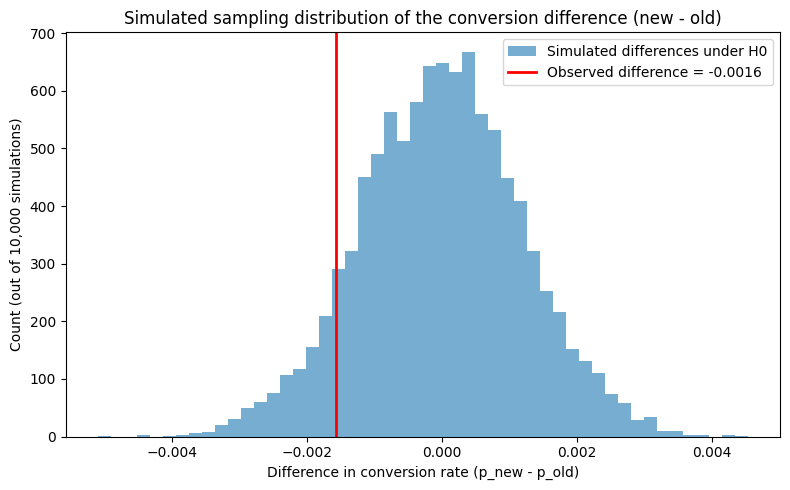

In [27]:
plt.figure(figsize=(8, 5))
plt.hist(p_diffs, bins=50, alpha=0.6, color='#1f77b4', label='Simulated differences under H0')
plt.axvline(x=obs_diff, color='red', linewidth=2, label=f'Observed difference = {obs_diff:.4f}')
plt.title('Simulated sampling distribution of the conversion difference (new - old)')
plt.xlabel('Difference in conversion rate (p_new - p_old)')
plt.ylabel('Count (out of 10,000 simulations)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/01_simulated_difference_histogram.png', dpi=150)
plt.show()

**j.** Proportion of `p_diffs` greater than the difference observed in `df2` (the p-value).

In [28]:
# p-value: share of simulated differences at least as large as the observed difference
p_value_sim = (p_diffs > obs_diff).mean()
print(f'Simulation p-value: {p_value_sim:.4f}')

Simulation p-value: 0.9081


**k.** What did we compute in part **j**, and what does it mean?

> This is the **p-value**: the probability of seeing a difference at least as large as the observed one if the two pages really convert equally. The p-value is far above the 0.05 Type I error rate, so we **fail to reject the null hypothesis**. The new page is not shown to convert better than the old page; the observed difference even slightly favors the old page. The exact p-value is printed by the cell above and summarized in the Results section.

**l. Built-in test**<br>
The same test can be done with a built-in function. First define:
- `convert_old`: number of conversions with the old page
- `convert_new`: number of conversions with the new page
- `n_old`: number of users shown the old page
- `n_new`: number of users shown the new page

In [29]:
import statsmodels.api as sm

# number of conversions with the old_page
convert_old = df2.query('(converted == 1) and (group == "control")')['user_id'].nunique()

# number of conversions with the new_page
convert_new = df2.query('(converted == 1) and (group == "treatment")')['user_id'].nunique()

# number of individuals who were shown the old_page
n_old = df2.query('group == "control"')['user_id'].nunique()

# number of individuals who received new_page
n_new = df2.query('group == "treatment"')['user_id'].nunique()

In [30]:
count_array = [convert_new, convert_old]
nobs_array = [n_new, n_old]

**m.** Compute the z-score and p-value with `sm.stats.proportions_ztest()` (one-sided, `alternative='larger'`).

In [31]:
import statsmodels.api as sm
# ToDo: Complete the sm.stats.proportions_ztest() method arguments
z_score, p_value = sm.stats.proportions_ztest(count_array, nobs_array, alternative='larger')
z_score, p_value

(-1.3109241984234394, 0.9050583127590245)

**n.** What do the z-score and p-value mean for the conversion rates of the old and new pages? Do they agree with parts **j** and **k**?

> The z-score is negative (the new page converts slightly less) and the p-value is far above 0.05, so we **fail to reject the null hypothesis**. This agrees with the simulation in parts j and k.

<a id='regression'></a>
## Part III - Logistic regression

### 3.1 Regression on page type
The same question can be answered with a regression.

**a.** Each row is either a conversion or no conversion, so which type of regression should be used?

> **Logistic regression**, because the outcome (`converted`) is binary (0 or 1).

**b.** Create two columns in `df2`:
 1. `intercept`: equal to `1` in every row.
 2. `ab_page`: dummy variable, `1` when the user received the treatment page, otherwise `0`.

In [32]:
df2['intercept'] = 1
df2['ab_page'] = pd.get_dummies(df2['group'])['treatment']
df2.head()

,user_id,timestamp,group,landing_page,converted,intercept,ab_page
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,1,False
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,1,False
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,1,True
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,1,True
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,1,False


**c.** Fit a logistic regression with `statsmodels` to predict whether a user converts.

In [33]:
model = sm.Logit(df2['converted'], df2[['intercept', 'ab_page']])
result = model.fit()

Optimization terminated successfully.
         Current function value: 0.366118
         Iterations 6


**d.** Model summary:

In [34]:
result.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: converted        Pseudo R-squared: 0.000      
Date:               2026-11-21 21:00 AIC:              212780.3502
No. Observations:   290584           BIC:              212801.5095
Df Model:           1                Log-Likelihood:   -1.0639e+05
Df Residuals:       290582           LL-Null:          -1.0639e+05
Converged:          1.0000           LLR p-value:      0.18988    
No. Iterations:     6.0000           Scale:            1.0000     
-------------------------------------------------------------------
              Coef.   Std.Err.      z      P>|z|    [0.025   0.975]
-------------------------------------------------------------------
intercept    -1.9888    0.0081  -246.6690  0.0000  -2.0046  -1.9730
ab_page      -0.0150    0.0114    -1.3109  0.1899  -0.0374   0.0074
==================================================================

"""

**e.** What is the p-value associated with `ab_page`? Why does it differ from the p-value in Part II?

> The p-value of `ab_page` is about 0.190, above the 0.05 Type I error rate, so we again **fail to reject the null hypothesis**. It differs from the Part II p-value (about 0.905) because the regression tests a two-sided hypothesis (is there any difference?), while Part II tests a one-sided hypothesis (is the new page better?).

**f.** Why consider other factors in the regression model? Are there disadvantages to adding more terms?

> Considering other factors is a good idea because the page is not the only thing that can affect conversion. For example, existing customers may react to a change (change aversion), or the country may matter. The disadvantage is that more terms can add noise and make the model harder to interpret, especially when the added terms are correlated with each other or not significant.

**g. Adding countries**<br>
Add a country effect next to the page effect:

1. Read `countries.csv` and join it to `df2` on `user_id` (`df_merged` below is called `df3`).
2. Create dummy variables for the three countries `['UK', 'US', 'CA']`, then fit the model and read the output.

In [35]:
# Read the countries file
countries = pd.read_csv('../data/countries.csv')

In [36]:
# Join with the df2 dataframe
new_data = countries.set_index('user_id').join(df2.set_index('user_id'))
new_data.head()

,country,timestamp,group,landing_page,converted,intercept,ab_page
user_id,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True


In [37]:
# Create the necessary dummy variables
dummies = pd.get_dummies(new_data['country'])
df3 = dummies.join(new_data)
df3.head()

,CA,UK,US,country,timestamp,group,landing_page,converted,intercept,ab_page
user_id,,,,,,,,,,
834778,False,True,False,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False
928468,False,False,True,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True
822059,False,True,False,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True
711597,False,True,False,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False
710616,False,True,False,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True


In [38]:
model1 = sm.Logit(df3['converted'], df3[['intercept', 'UK', 'CA']])
results = model1.fit()
results.summary2()

Optimization terminated successfully.
         Current function value: 0.366116
         Iterations 6


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: converted        Pseudo R-squared: 0.000      
Date:               2026-11-21 21:00 AIC:              212780.8333
No. Observations:   290584           BIC:              212812.5723
Df Model:           2                Log-Likelihood:   -1.0639e+05
Df Residuals:       290581           LL-Null:          -1.0639e+05
Converged:          1.0000           LLR p-value:      0.19835    
No. Iterations:     6.0000           Scale:            1.0000     
-------------------------------------------------------------------
              Coef.   Std.Err.      z      P>|z|    [0.025   0.975]
-------------------------------------------------------------------
intercept    -1.9967    0.0068  -292.3145  0.0000  -2.0101  -1.9833
UK            0.0099    0.0133     0.7458  0.4558  -0.0161   0.0360
CA           -0.0408    0.0269    -1.5178  0.1291  -0.0935   0.0119
==================================================================

"""

In [39]:
model2 = sm.Logit(df3['converted'], df3[['intercept', 'ab_page', 'UK', 'CA']])
results = model2.fit()
results.summary2()

Optimization terminated successfully.
         Current function value: 0.366113
         Iterations 6


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: converted        Pseudo R-squared: 0.000      
Date:               2026-11-21 21:00 AIC:              212781.1253
No. Observations:   290584           BIC:              212823.4439
Df Model:           3                Log-Likelihood:   -1.0639e+05
Df Residuals:       290580           LL-Null:          -1.0639e+05
Converged:          1.0000           LLR p-value:      0.17599    
No. Iterations:     6.0000           Scale:            1.0000     
-------------------------------------------------------------------
              Coef.   Std.Err.      z      P>|z|    [0.025   0.975]
-------------------------------------------------------------------
intercept    -1.9893    0.0089  -223.7628  0.0000  -2.0067  -1.9718
ab_page      -0.0149    0.0114    -1.3069  0.1912  -0.0374   0.0075
UK            0.0099    0.0133     0.7433  0.4573  -0.0162   0.0359
CA           -0.0408    0.0269    -1.5161  0.1295  -0.0934   0.0119
==================================================================

"""

> In these models the country predictors (UK, CA) have high p-values, so country has no significant effect on conversion by itself. Adding `ab_page` to the model changes nothing: the page effect is still not significant. We still fail to reject the null hypothesis.

**h. Page x country interaction**<br>
Test whether the effect of the page differs by country: create the interaction columns and fit the new model.

In [40]:
df3['UK_new_page'] = df3['ab_page']* df3['UK']
df3['CA_new_page'] = df3['ab_page']* df3['CA']
df3.head()

,CA,UK,US,country,timestamp,group,landing_page,converted,intercept,ab_page,UK_new_page,CA_new_page
user_id,,,,,,,,,,,,
834778,False,True,False,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False,False,False
928468,False,False,True,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True,False,False
822059,False,True,False,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True,True,False
711597,False,True,False,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False,False,False
710616,False,True,False,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True,True,False


In [41]:
# Fit your model, and summarize the results
model3 = sm.Logit(df3['converted'], df3[['intercept', 'ab_page', 'UK', 'CA', 'UK_new_page', 'CA_new_page']])
results = model3.fit()
results.summary2()

Optimization terminated successfully.
         Current function value: 0.366109
         Iterations 6


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: converted        Pseudo R-squared: 0.000      
Date:               2026-11-21 21:00 AIC:              212782.6602
No. Observations:   290584           BIC:              212846.1381
Df Model:           5                Log-Likelihood:   -1.0639e+05
Df Residuals:       290578           LL-Null:          -1.0639e+05
Converged:          1.0000           LLR p-value:      0.19199    
No. Iterations:     6.0000           Scale:            1.0000     
-------------------------------------------------------------------
              Coef.   Std.Err.      z      P>|z|    [0.025   0.975]
-------------------------------------------------------------------
intercept    -1.9865    0.0096  -206.3440  0.0000  -2.0053  -1.9676
ab_page      -0.0206    0.0137    -1.5052  0.1323  -0.0473   0.0062
UK           -0.0057    0.0188    -0.3057  0.7598  -0.0426   0.0311
CA           -0.0175    0.0377    -0.4652  0.6418  -0.0914   0.0563
UK_new_page   0.0314    0.0266     1.1807  0.2377  -0.0207   0.0835
CA_new_page  -0.0469    0.0538    -0.8718  0.3833  -0.1523   0.0585
==================================================================

"""

> Adding the interaction terms does not improve the model: every coefficient is still not significant. There is still no evidence to reject the null hypothesis, so the old page should be kept.

In [42]:
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest

summary = pd.DataFrame({
    'Metric': [
        'Rows in raw data',
        'Mismatched rows removed',
        'Unique users after cleaning',
        'Overall conversion rate',
        'Control (old page) conversion rate',
        'Treatment (new page) conversion rate',
        'Observed difference (new - old), percentage points',
        'p-value, simulation (10,000 draws, seed 42)',
        'z-score, proportions z-test',
        'p-value, proportions z-test (one-sided)',
        'p-value of ab_page, logistic regression',
    ],
    'Value': [
        f'{len(df):,}',
        f'{len(df) - len(df2) - 1:,}',
        f'{df2.user_id.nunique():,}',
        f'{df2.converted.mean():.2%}',
        f'{b:.2%}',
        f'{c:.2%}',
        f'{obs_diff * 100:.3f}',
        f'{p_value_sim:.3f}',
        f'{z_score:.2f}',
        f'{p_value:.3f}',
        f'{result.pvalues["ab_page"]:.3f}',
    ]
})
summary.to_csv('../results_summary.csv', index=False)
summary

,Metric,Value
0,Rows in raw data,"294,478"
1,Mismatched rows removed,"3,893"
2,Unique users after cleaning,"290,584"
3,Overall conversion rate,11.96%
4,Control (old page) conversion rate,12.04%
5,Treatment (new page) conversion rate,11.88%
6,"Observed difference (new - old), percentage po...",-0.158
7,"p-value, simulation (10,000 draws, seed 42)",0.908
8,"z-score, proportions z-test",-1.31
9,"p-value, proportions z-test (one-sided)",0.905


<a id='results'></a>
## Results summary

The table above is computed from the data above and also saved to `results_summary.csv`.

**Recommendation: keep the old page.** At a 0.05 significance level all three tests (simulation, z-test, logistic regression) fail to reject the null hypothesis. The new page does not convert better than the old page: it converted slightly less (-0.158 percentage points), and the difference is not statistically significant. Country and the page x country interaction did not change this conclusion.

**Limits:** this is one experiment on the data provided, with no information on how long it ran or on user segments beyond country. An extended test could be considered, but this data gives no reason to switch pages.